In [17]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import os
import fastparquet
from datetime import datetime

# limpar terminal
def limpar_terminal():
    os.system('cls' if os.name == 'nt' else 'clear')

limpar_terminal()

ENTRADA DE DADOS

In [18]:
# CONFIG DO PL

pl.Config.set_tbl_rows(-1)
pl.Config.set_tbl_cols(-1)
pl.Config.set_float_precision(2)
pl.Config.set_thousands_separator('.')
pl.Config.set_decimal_separator(',')

polars.config.Config

In [21]:

ENDERECO_DADOS = "./../.dados/Auxilio"


## EXISTE PARQUET?

validador_parquet = [
    arquivo for arquivo in os.listdir(ENDERECO_DADOS) 
    if arquivo.endswith('.parquet')
]

df_auxilio = None



# SE NAO

if not validador_parquet: 
    # Pega a lista com arquivos e filtra apenas os .csv
    lista_arquivos = [arquivo for arquivo in os.listdir(ENDERECO_DADOS) if arquivo.endswith('.csv')]

    # Concatenando todos em um único DataFrame
    for arquivo in lista_arquivos:
        caminho_completo = os.path.join(ENDERECO_DADOS, arquivo)
        df_temp = pl.read_csv(caminho_completo, separator=';', encoding='iso-8859-1')
        
        if df_auxilio is None:
            df_auxilio = df_temp
        else:
            df_auxilio = pl.concat([df_auxilio, df_temp])
    
    # Tratar valores quantitativos
    df_auxilio = df_auxilio.with_columns(
        pl.col("VALOR PARCELA")
        .str.replace(",", ".")
        .cast(pl.Float64)
    )

    # Transformar em parquet
    df_auxilio.write_parquet('./../.dados/Auxilio/auxilio.parquet')



# SE SIM
else:
    
    df_lazy_plan = (
        pl.scan_parquet('./../.dados/Auxilio/auxilio.parquet')
        .select(['NOME MUNICÍPIO', 'VALOR PARCELA'])
        .group_by('NOME MUNICÍPIO')
        .agg(pl.col('VALOR PARCELA').sum())
        .sort('VALOR PARCELA', descending=True)
    )

    df_auxilio = df_lazy_plan.collect()


SAÍDA DE DADOS

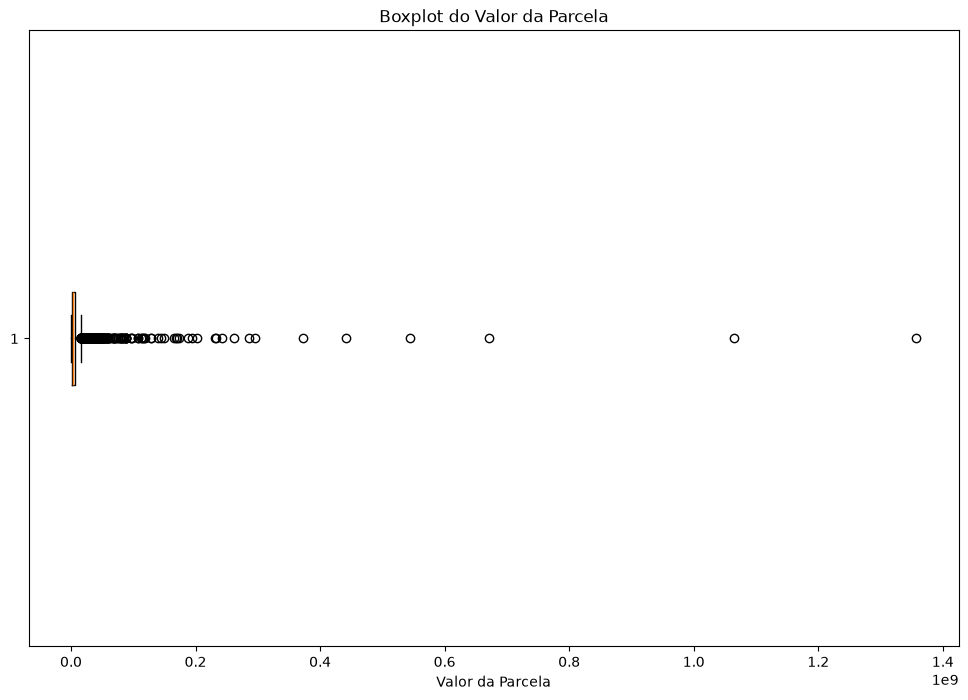

In [22]:

# print(df_auxilio)

# valor_total = df_auxilio['VALOR PARCELA'].sum()
# print(f"Valor total: {valor_total:,.2f}".replace(",", "X").replace(".", ",").replace("X", "."))

# criar um boxplot para a coluna valor parcela

plt.figure(figsize=(12, 8))
plt.boxplot(df_auxilio['VALOR PARCELA'], orientation="horizontal")
plt.title("Boxplot do Valor da Parcela")
plt.xlabel("Valor da Parcela")

plt.show()
